In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import sys
sys.path.append('../')
from src.ConstitutiveModel import DebyeModel
from src.PlaneWave import PlaneWave

%reload_ext autoreload
%autoreload 2

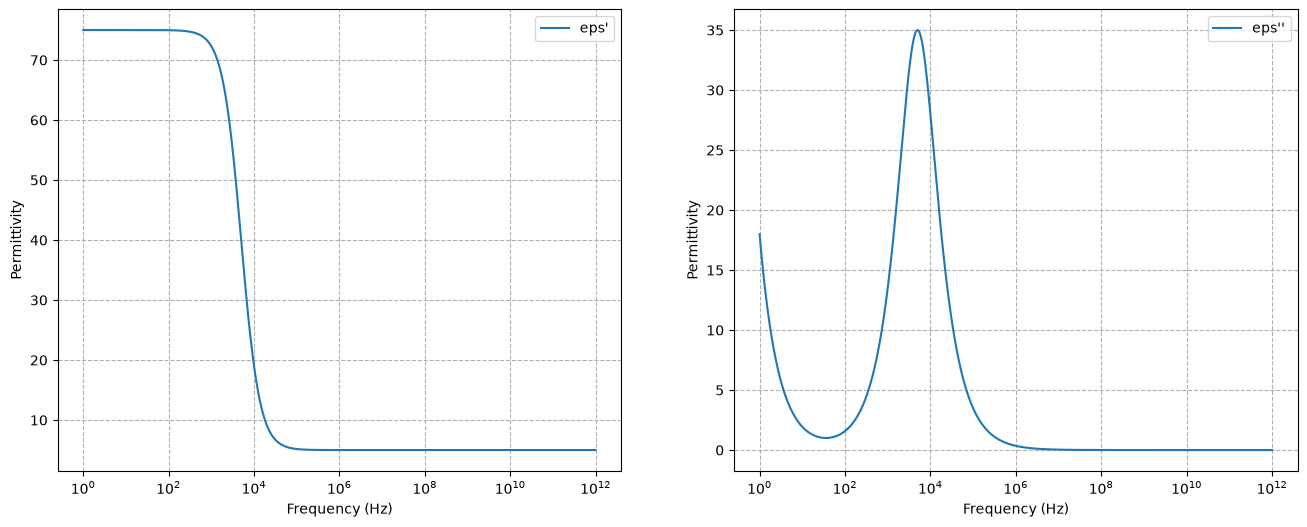

In [ ]:
eps_infty = 5
eps_s = 75
delta_eps = eps_s - eps_infty
sigma_s = 1e-9
fr = 5e3 
omega_r = 2 * np.pi * fr
tau = 1 / omega_r
eps_0 = 8.854187817e-12
omega = 2 * np.pi * np.logspace(0, 12, 1000)  # frequency range from 1 kHz to 1 GHz
f = omega / (2 * np.pi)

debye_model = DebyeModel(eps_infty, delta_eps, sigma_s, eps_0, tau)

eps, eps_p, eps_pp = debye_model.debye_single(omega)

plt.figure(figsize=(16, 6))
plt.subplot(1,2,1)
plt.semilogx(f, eps_p, label='eps\'')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Permittivity')
plt.legend()
plt.grid(True, which='both', ls='--')

plt.subplot(1,2,2)
plt.semilogx(f, eps_pp, label='eps\'\'')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Permittivity')
plt.legend()
plt.grid(True, which='both', ls='--')
plt.show()


# Transfer function

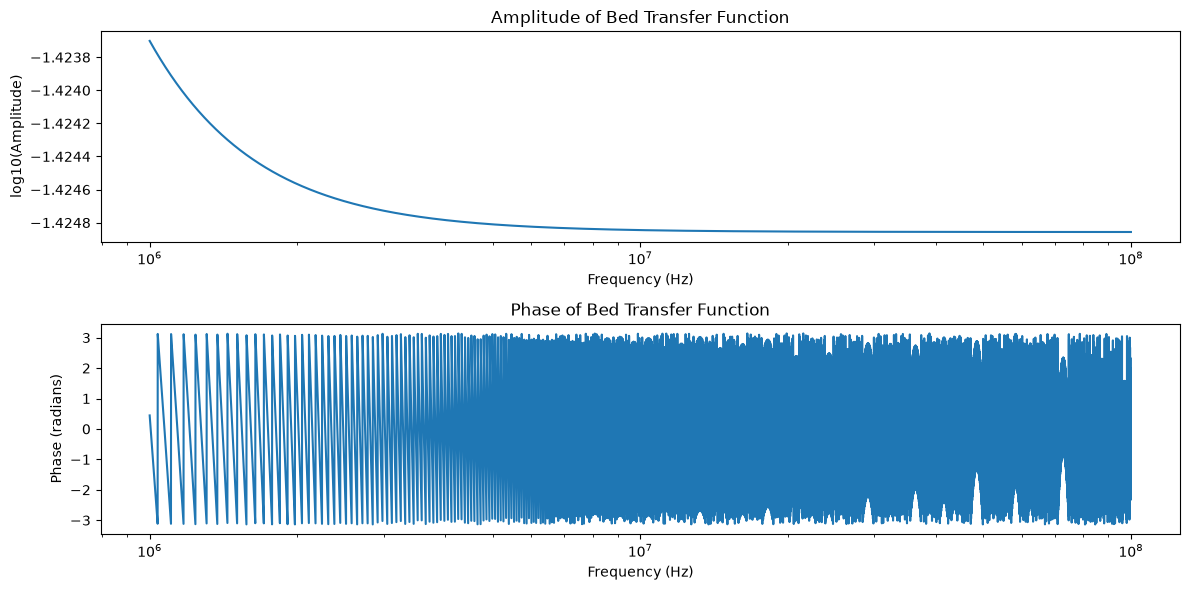

In [39]:
# consider plane wave solution in 1D frequency domain -> diffusive wave
H = 2e3 # ice thickness
mu = 4 * np.pi * 1e-7 # magnetic permeability of free space
eps_0 = 8.854187817e-12 # permittivity of free space
sigma = 1e-9
f_range     = np.logspace(6, 8, 10000)  # frequency range from 1 MHz to 1 GHz
omega_range = 2 * np.pi * f_range

# only use the first output (total)
model_specific = lambda omega: debye_model.debye_single(omega)[0]

plane_wave = PlaneWave(
    H = H, 
    mu = mu, 
    sigma = sigma, 
    eps_0 = eps_0,
    model = model_specific
)
bed_transfer_fn = plane_wave.bed_transfer(omega_range)

# plot the amplitude and phase of the transfer function
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.semilogx(f_range, np.log10(np.abs(bed_transfer_fn)))
plt.xlabel('Frequency (Hz)')
plt.ylabel('log10(Amplitude)')
plt.title('Amplitude of Bed Transfer Function')

plt.subplot(2, 1, 2)
plt.semilogx(f_range, np.angle(bed_transfer_fn))
plt.xlabel('Frequency (Hz)')
plt.ylabel('Phase (radians)')
plt.title('Phase of Bed Transfer Function')
plt.tight_layout()
plt.savefig('../fig/bed_transfer_function.png')
plt.show()

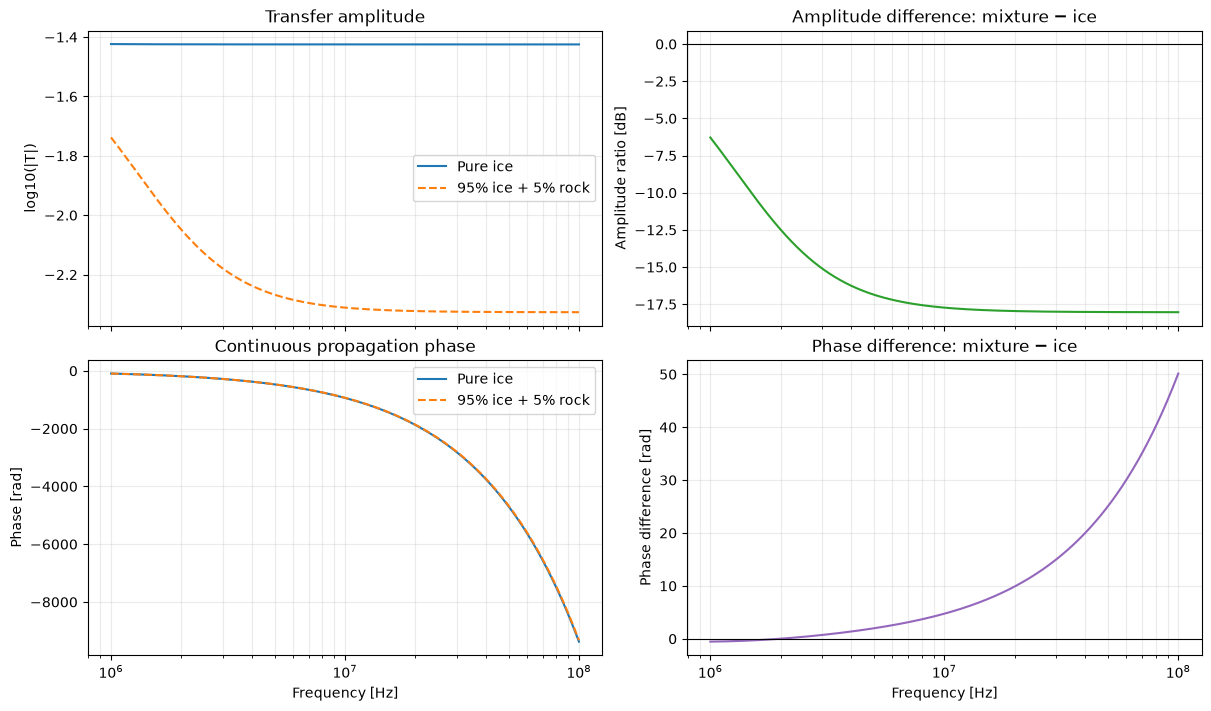

In [43]:
from src.ConstitutiveModel import MixingModel

# These are sensitivity-test values, not a calibrated rock model.
rock_eps_infty = 4.0
rock_eps_s = 8.0
rock_fr = 1e6       # relaxation frequency [Hz]
rock_sigma = 1e-5  # DC conductivity [S/m]

rock_model = DebyeModel(
    eps_infty=rock_eps_infty,
    delta_eps=rock_eps_s - rock_eps_infty,
    sigma_s=rock_sigma,
    eps_0=eps_0,
    tau=1 / (2 * np.pi * rock_fr),
)

# Include your additional ice conductivity in the host material.
def ice_total_model(omega):
    return (
        debye_model.debye_single(omega)[0]
        # - 1j * sigma / (eps_0 * omega)
    )

rock_specific = lambda omega: rock_model.debye_single(omega)[0]

mixing_model = MixingModel(
    inclusion_model=rock_specific,
    host_model=ice_total_model,
    fraction=0.05,  # rock volume fraction
)

mixture_wave = PlaneWave(
    H=H,
    mu=mu,
    sigma=0.0,  # Both constituent conductivities are already included.
    eps_0=eps_0,
    model=mixing_model.maxwell_garnett,
)

# Transfer functions: your existing pure-ice wave and the mixture.
gamma_ice = plane_wave.gamma(omega_range)
gamma_mix = mixture_wave.gamma(omega_range)

transfer_ice = plane_wave.bed_transfer(omega_range)
transfer_mix = mixture_wave.bed_transfer(omega_range)

# Calculate logarithmic amplitude directly to avoid underflow.
log_amp_ice = -gamma_ice.real * H / np.log(10)
log_amp_mix = -gamma_mix.real * H / np.log(10)

# Continuous phase directly from gamma: no phase-unwrapping ambiguity.
phase_ice = -gamma_ice.imag * H
phase_mix = -gamma_mix.imag * H

delta_amp_db = 20 * (log_amp_mix - log_amp_ice)
delta_phase = phase_mix - phase_ice

fig, axes = plt.subplots(
    2, 2, figsize=(12, 7), sharex=True, constrained_layout=True
)

axes[0, 0].semilogx(f_range, log_amp_ice, label="Pure ice")
axes[0, 0].semilogx(
    f_range, log_amp_mix, "--", label="95% ice + 5% rock"
)
axes[0, 0].set_title("Transfer amplitude")
axes[0, 0].set_ylabel("log10(|T|)")
axes[0, 0].legend()

axes[0, 1].semilogx(f_range, delta_amp_db, color="tab:green")
axes[0, 1].axhline(0, color="black", linewidth=0.8)
axes[0, 1].set_title("Amplitude difference: mixture − ice")
axes[0, 1].set_ylabel("Amplitude ratio [dB]")

axes[1, 0].semilogx(f_range, phase_ice, label="Pure ice")
axes[1, 0].semilogx(
    f_range, phase_mix, "--", label="95% ice + 5% rock"
)
axes[1, 0].set_title("Continuous propagation phase")
axes[1, 0].set_ylabel("Phase [rad]")
axes[1, 0].legend()

axes[1, 1].semilogx(f_range, delta_phase, color="tab:purple")
axes[1, 1].axhline(0, color="black", linewidth=0.8)
axes[1, 1].set_title("Phase difference: mixture − ice")
axes[1, 1].set_ylabel("Phase difference [rad]")

for ax in axes.flat:
    ax.grid(True, which="both", alpha=0.25)

for ax in axes[1, :]:
    ax.set_xlabel("Frequency [Hz]")

plt.savefig('../fig/pureice_vs_mixture.png')
plt.show()

